In [18]:
from google.colab import files
uploaded = files.upload()

Saving monthly-car-sales.csv to monthly-car-sales (1).csv


In [19]:
import pandas as pd

df = pd.read_csv('monthly-car-sales.csv')

df.head()

,Month,Sales
0,1960-01,6550
1,1960-02,8728
2,1960-03,12026
3,1960-04,14395
4,1960-05,14587


In [20]:

print(df.info())

df['Month'] = pd.to_datetime(df['Month'])

print("\nMissing Values:")
print(df.isnull().sum())


df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Month   108 non-null    object
 1   Sales   108 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ KB
None

Missing Values:
Month    0
Sales    0
dtype: int64


,Month,Sales
0,1960-01-01,6550
1,1960-02-01,8728
2,1960-03-01,12026
3,1960-04-01,14395
4,1960-05-01,14587


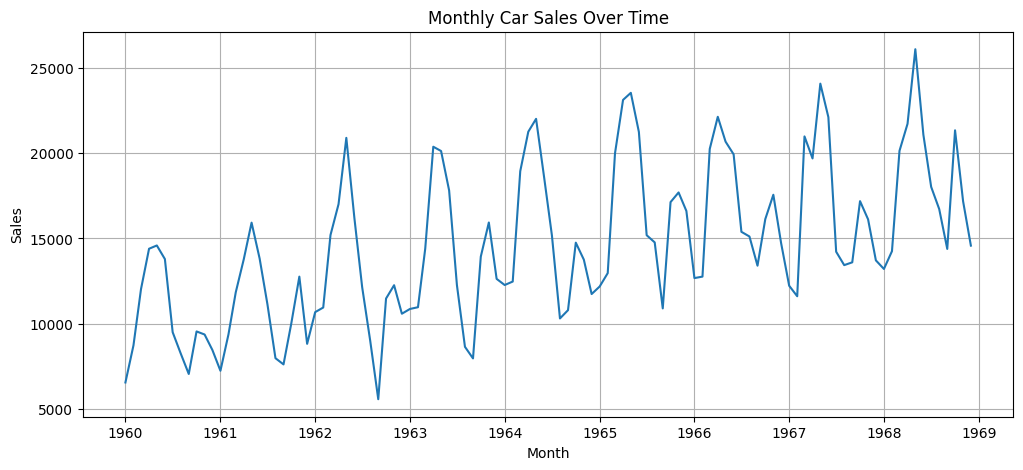

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df['Month'], df['Sales'])
plt.title('Monthly Car Sales Over Time')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(True)
plt.show()

In [22]:
# Create a numeric time index
df['Time'] = range(len(df))

df.head()

,Month,Sales,Time
0,1960-01-01,6550,0
1,1960-02-01,8728,1
2,1960-03-01,12026,2
3,1960-04-01,14395,3
4,1960-05-01,14587,4


In [23]:
from sklearn.linear_model import LinearRegression

# Input and output
X = df[['Time']]
y = df['Sales']

# Train model
model = LinearRegression()
model.fit(X, y)

print("Model trained successfully!")

Model trained successfully!


In [24]:
df['Predicted_Sales'] = model.predict(X)

df.head()

,Month,Sales,Time,Predicted_Sales
0,1960-01-01,6550,0,10250.777268
1,1960-02-01,8728,1,10331.979770
2,1960-03-01,12026,2,10413.182272
3,1960-04-01,14395,3,10494.384773
4,1960-05-01,14587,4,10575.587275


In [25]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y, df['Predicted_Sales'])
r2 = r2_score(y, df['Predicted_Sales'])

print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 2))

Mean Absolute Error: 3154.38
R2 Score: 0.32


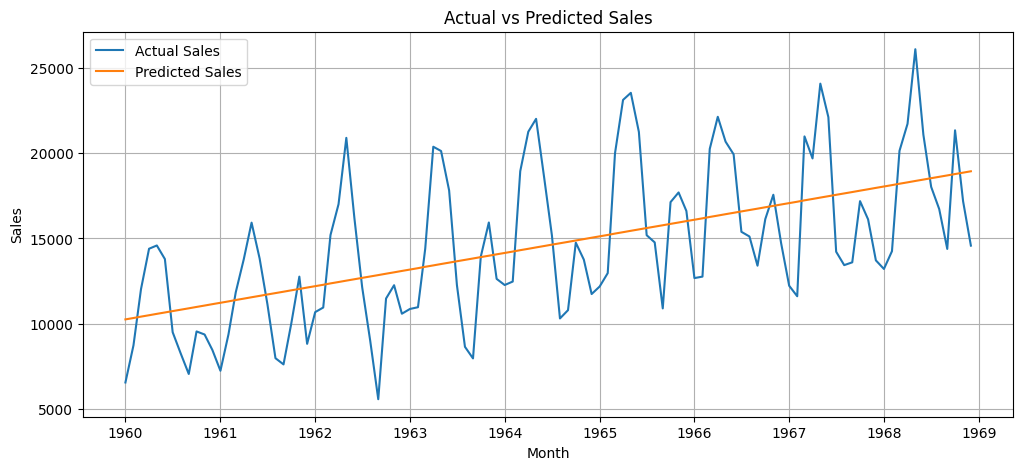

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df['Month'], df['Sales'], label='Actual Sales')
plt.plot(df['Month'], df['Predicted_Sales'], label='Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [27]:

future_time = [[i] for i in range(len(df), len(df) + 12)]


future_predictions = model.predict(future_time)


for i, pred in enumerate(future_predictions, start=1):
    print(f"Month {i}: {pred:.2f}")

Month 1: 19020.65
Month 2: 19101.85
Month 3: 19183.05
Month 4: 19264.25
Month 5: 19345.46
Month 6: 19426.66
Month 7: 19507.86
Month 8: 19589.06
Month 9: 19670.27
Month 10: 19751.47
Month 11: 19832.67
Month 12: 19913.87


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


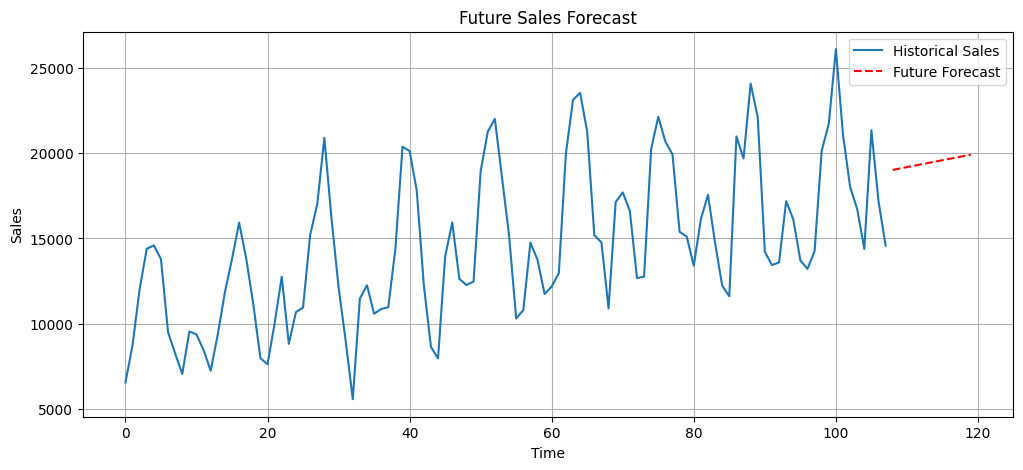

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df['Time'], df['Sales'], label='Historical Sales')

future_x = list(range(len(df), len(df) + 12))
plt.plot(future_x, future_predictions, 'r--', label='Future Forecast')

plt.title('Future Sales Forecast')
plt.xlabel('Time')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

This project used historical monthly car sales data to build a predictive analytics model using Linear Regression. The dataset was cleaned and analyzed to identify trends. The model successfully captured the overall growth trend and was used to forecast future sales for the next 12 months. The results demonstrate how predictive analytics can support data-driven forecasting and trend analysis.